<a href="https://colab.research.google.com/github/Rogerkamana/Assignment4_rk/blob/main/Assignment_9_Unsupervised_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 9 | Unsupervised Learning
**Roger Kamana · Willis College**

## 1. Dataset selection and preprocessing
The [UCI Wine Quality dataset](https://doi.org/10.24432/C56S3T) can support regression on the sensory quality score. Here we use the red Portuguese Vinho Verde subset to discover groups based on physicochemical properties. We reserve quality for description after fitting. All 11 inputs are numeric.

link to:
GitHub:

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

url = ('https://archive.ics.uci.edu/ml/machine-learning-databases/'
       'wine-quality/winequality-red.csv')
raw = pd.read_csv(url, sep=';')
features = raw.drop(columns='quality')
print(f'Raw rows: {len(raw):,} | Features: {features.shape[1]}')
print(f'Missing feature values: {features.isna().sum().sum()}')
# Repeated chemical profiles would otherwise receive extra weight.
keep = ~features.duplicated()
data = raw.loc[keep].reset_index(drop=True)
X = data.drop(columns='quality')
assert all(pd.api.types.is_numeric_dtype(column) for _, column in X.items())
print(f'Removed repeated profiles: {(~keep).sum()} | Kept: {len(X):,}')
# Median imputation is defined for future missing inputs. No encoding is needed.
preprocessor = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
Z = preprocessor.fit_transform(X)

Raw rows: 1,599 | Features: 11
Missing feature values: 0
Removed repeated profiles: 240 | Kept: 1,359


## 2. Clustering
Fit K-means with 20 initializations and Ward agglomerative clustering for $k=2$ through $10$. Both use Euclidean geometry on standardized features. Select the highest silhouette within each family. The K-means inertia curve is a secondary diagnostic.

,method,k,silhouette,Davies–Bouldin,Calinski–Harabasz,inertia
0,K-means,2,0.205,1.897,308.258,12181.774
1,Ward,2,0.206,1.795,216.878,NaN
2,K-means,3,0.188,1.752,267.294,10721.976
3,Ward,3,0.145,2.029,216.524,NaN
4,K-means,4,0.205,1.494,254.673,9559.085
5,Ward,4,0.151,1.705,204.406,NaN
6,K-means,5,0.189,1.463,249.737,8602.383
7,Ward,5,0.123,1.653,195.525,NaN
8,K-means,6,0.191,1.408,238.013,7953.399
9,Ward,6,0.133,1.596,187.301,NaN


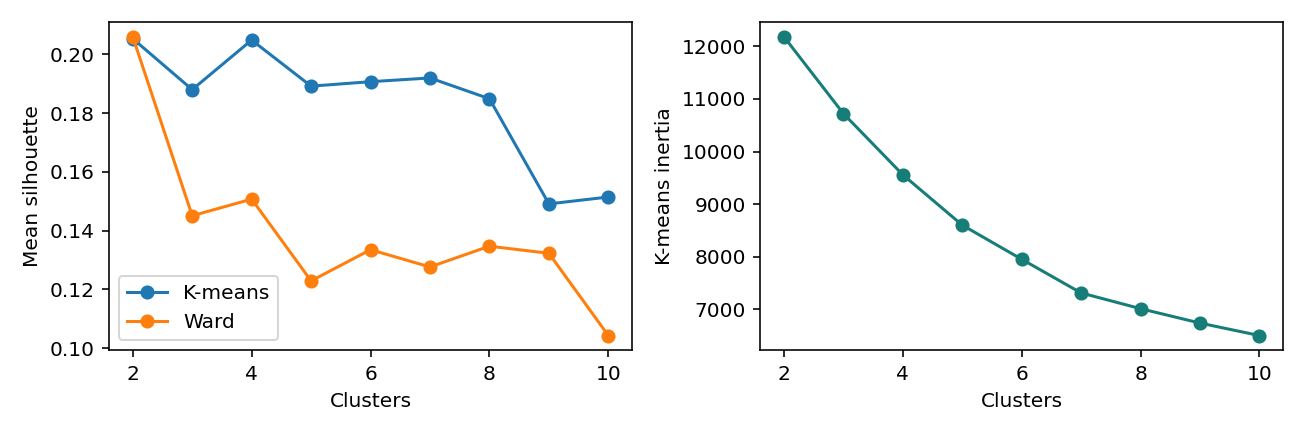

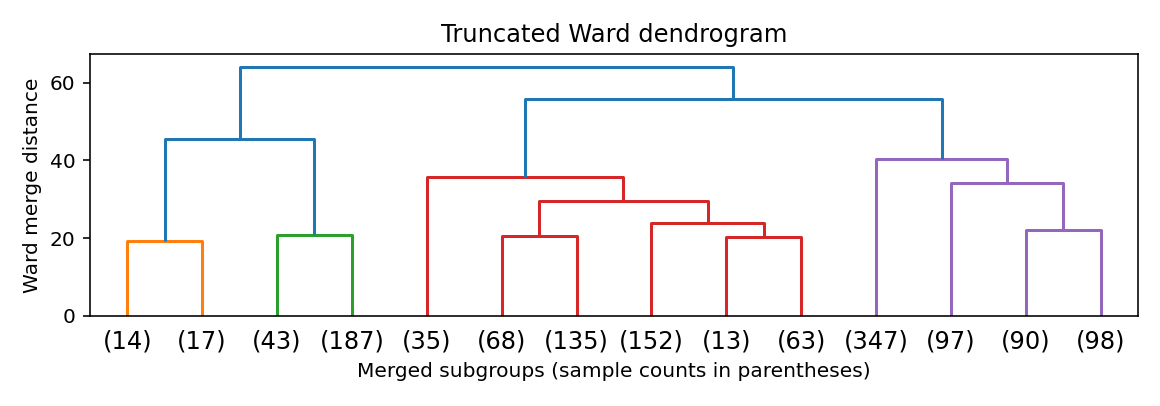

In [ ]:
models, labels, scores = {}, {}, []
for k in range(2, 11):
    candidates = {'K-means': KMeans(n_clusters=k, n_init=20, random_state=42),
                  'Ward': AgglomerativeClustering(n_clusters=k, linkage='ward')}
    for name, model in candidates.items():
        key = (name, k)
        group = model.fit_predict(Z)
        models[key], labels[key] = model, group
        scores.append({
            'method': name, 'k': k, 'silhouette': silhouette_score(Z, group),
            'Davies–Bouldin': davies_bouldin_score(Z, group),
            'Calinski–Harabasz': calinski_harabasz_score(Z, group),
            'inertia': getattr(model, 'inertia_', np.nan),
        })

results = pd.DataFrame(scores)
best = (results.sort_values('silhouette', ascending=False)
        .drop_duplicates('method').reset_index(drop=True))
display(results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for name, rows in results.groupby('method'):
    axes[0].plot(rows.k, rows.silhouette, marker='o', label=name)
axes[0].set(xlabel='Clusters', ylabel='Mean silhouette')
axes[0].legend()
km = results.query("method == 'K-means'")
axes[1].plot(km.k, km.inertia, marker='o', color='#167d79')
axes[1].set(xlabel='Clusters', ylabel='K-means inertia')
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 2.8))
dendrogram(linkage(Z, method='ward'), truncate_mode='lastp', p=14, ax=ax)
ax.set(xlabel='Merged subgroups (sample counts in parentheses)',
       ylabel='Ward merge distance', title='Truncated Ward dendrogram')
fig.tight_layout()
plt.show()

## 3. Dimensionality reduction
Fit PCA to the same standardized inputs and show the selected partitions in a common two-dimensional view. Cluster fitting and model selection use all 11 inputs.

Total variance in two components: 45.6%


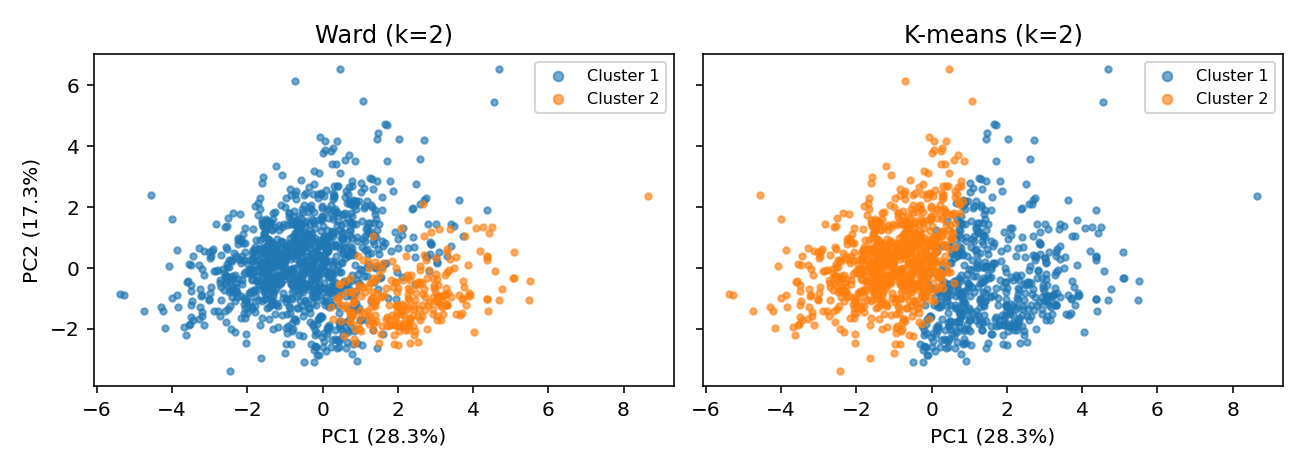

In [ ]:
pca = PCA(n_components=2)
coordinates = pca.fit_transform(Z)
variance = 100 * pca.explained_variance_ratio_
fig, axes = plt.subplots(1, 2, figsize=(9, 3.25), sharex=True, sharey=True)
for row, ax in zip(best.itertuples(), axes):
    group = labels[row.method, row.k]
    for cluster in np.unique(group):
        points = coordinates[group == cluster]
        ax.scatter(*points.T, s=10, alpha=0.62, label=f'Cluster {cluster + 1}')
    ax.set(title=f'{row.method} (k={row.k})', xlabel=f'PC1 ({variance[0]:.1f}%)')
    ax.legend(fontsize=8, markerscale=1.5)
axes[0].set_ylabel(f'PC2 ({variance[1]:.1f}%)')
fig.tight_layout()
plt.show()
print(f'Total variance in two components: {variance.sum():.1f}%')

## 4. Evaluation and interpretation
Silhouette measures separation relative to within-cluster cohesion and is the selection metric. Higher values are preferred. Lower Davies–Bouldin and higher Calinski–Harabasz scores indicate better separation by their respective criteria. Evaluate on the 11 standardized features. Adjusted Rand index describes agreement between the methods on the same records.

In [ ]:
display(best.drop(columns='inertia').round(3))
winner = best.iloc[0]
winning_key = (winner.method, int(winner.k))
winning_labels = labels[winning_key]
first, second = [labels[r.method, r.k] for r in best.itertuples()]
agreement = adjusted_rand_score(first, second)
print(f'Adjusted Rand index: {agreement:.3f}')
for r in best.itertuples():
    print(f'{r.method} cluster sizes: {np.bincount(labels[r.method, r.k]).tolist()}')
profiles = data.assign(cluster=winning_labels + 1).groupby('cluster')
display(profiles.size().rename('records').to_frame())
display(profiles.mean().round(3))
standard_profiles = pd.DataFrame(Z, columns=X.columns).groupby(winning_labels).mean()
display(standard_profiles.round(2))

Adjusted Rand index: 0.332
Ward cluster sizes: [1098, 261]
K-means cluster sizes: [543, 816]


,method,k,silhouette,Davies–Bouldin,Calinski–Harabasz
0,Ward,2,0.206,1.795,216.878
1,K-means,2,0.205,1.897,308.258


,records
cluster,
1,1098
2,261


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
cluster,,,,,,,,,,,,
1,7.768,0.557,0.216,2.490,0.082,17.394,51.161,0.996,3.345,0.637,10.414,5.560
2,10.592,0.415,0.509,2.665,0.115,9.579,28.590,0.998,3.163,0.752,10.508,5.889


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,-0.31,0.15,-0.29,-0.02,-0.13,0.14,0.13,-0.19,0.22,-0.13,-0.02
1,1.31,-0.63,1.21,0.10,0.55,-0.60,-0.55,0.79,-0.95,0.55,0.07


Ward selected 2 clusters with silhouette 0.2060 versus 0.2053 for K-means. Both values indicate substantial overlap. Ward had the lower Davies–Bouldin score, while K-means had the higher Calinski–Harabasz score. The adjusted Rand index of 0.332 shows that selecting two groups still produced different assignments. The smaller Ward group (261 of 1,359 samples) had higher mean fixed acidity (10.59 vs. 7.77) and lower mean volatile acidity (0.415 vs. 0.557). Its average sensory quality score was 5.89 versus 5.56. This comparison is descriptive and uses the quality scores only after fitting.

## 5. Deployment and monitoring
A wine laboratory could pilot the silhouette-selected Ward solution. Fit a nearest-centroid assignment rule on standardized Ward groups and validate it on later batches against reference Ward assignments from batch reclustering, aligning group IDs before comparison. K-means is a fallback if Ward assignments prove unstable. Package the feature schema, fitted imputer, scaler and centroids together. Validate the 11 named inputs and their units. Track assignment distance and flag distant samples for review. Batch scoring is suitable for daily lab runs and a lightweight API can support immediate routing. The centroid rule approximates Ward membership and must be validated before release.

Collect baseline latency, throughput, feature missingness, range violations, centroid distances and cluster proportions. Track those metrics by lab and time period so a calibration change can be distinguished from a shift in wine production. Review weekly and investigate sustained changes. Retrain periodically or after confirmed drift, compare the candidate with the current model on a recent time-based validation batch, and keep the last version available for rollback.

## 6. Report and source
The companion PDF summarizes the analysis in two pages. See the repository README for instructions.

Cortez et al. (2009). *Wine Quality*. UCI Machine Learning Repository. [https://doi.org/10.24432/C56S3T](https://doi.org/10.24432/C56S3T).